<a href="https://colab.research.google.com/github/sindhura-nk/Machine-Learning-1663/blob/main/K_Means_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## K Means Clustering

In [1]:
path = r"https://raw.githubusercontent.com/sindhura-nk/Datasets/refs/heads/main/Mall_Customers.csv"
import pandas as pd
df = pd.read_csv(path)
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## perform basic data quality checks

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [3]:
# missing data
df.isna().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [4]:
# duplciates
df.duplicated().sum()

np.int64(0)

In [5]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

## Consider features required for X (Cluster formation)

X: age,income and spending

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

X = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]
X.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [7]:
X.columns = ['Age','Income','Spending']
X.head()

,Age,Income,Spending
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [8]:
num_pipe = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler()
).set_output(transform='pandas')

num_pipe

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler())])

In [9]:
X_pre = num_pipe.fit_transform(X)
X_pre.head()

,Age,Income,Spending
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980


## K Means CLuster

In [10]:
from sklearn.cluster import KMeans
model = KMeans(n_clusters=4)
model.fit(X_pre)

KMeans(n_clusters=4)

In [11]:
clusters4 = model.predict(X_pre)
clusters4

array([3, 3, 3, 3, 3, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 3, 3, 1, 3, 3, 3,
       1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3,
       1, 3, 1, 3, 3, 3, 1, 3, 3, 1, 1, 1, 1, 1, 3, 1, 1, 3, 1, 1, 1, 3,
       1, 1, 3, 3, 1, 1, 1, 1, 1, 3, 1, 1, 3, 1, 1, 3, 1, 1, 3, 1, 1, 3,
       3, 1, 1, 3, 1, 1, 3, 3, 1, 3, 1, 3, 3, 1, 1, 3, 1, 3, 1, 1, 1, 1,
       1, 3, 2, 3, 3, 3, 1, 1, 1, 1, 3, 2, 0, 0, 2, 0, 2, 0, 1, 0, 2, 0,
       2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0,
       2, 0, 2, 0, 2, 0, 1, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0,
       2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0,
       2, 0], dtype=int32)

## Evaluation Metric: Inertia

In [12]:
model.inertia_

205.22514747675913

## Choosing the best cluster with the help of Elbow method

In [13]:
pip install yellowbrick

## Restart the kernel and run all the cells

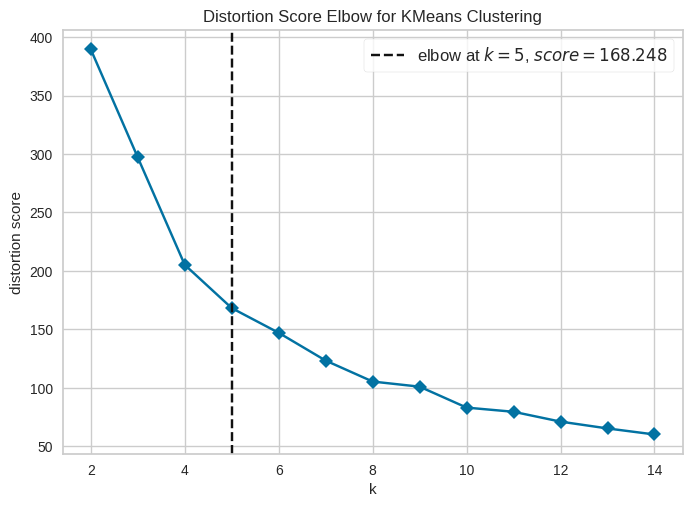

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [16]:
from yellowbrick.cluster import kelbow_visualizer
base_model = KMeans()
visualizer = kelbow_visualizer(base_model,X_pre,k=(2,15),timings=False)
visualizer.show()

## The value of k from the eblow method is 5.
### Rebuild the model with number of clusters as 5

In [17]:
final_model = KMeans(n_clusters=5)
final_model.fit(X_pre)

KMeans(n_clusters=5)

In [18]:
labels = final_model.predict(X_pre)
labels

array([1, 4, 1, 4, 1, 4, 1, 4, 0, 4, 0, 4, 0, 4, 1, 4, 1, 4, 0, 4, 1, 4,
       0, 4, 0, 4, 0, 4, 1, 4, 0, 4, 0, 4, 0, 4, 0, 4, 1, 4, 0, 4, 0, 1,
       0, 4, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1,
       0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1,
       1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 2, 1, 2, 3, 2, 3, 2, 3, 2,
       1, 2, 3, 2, 3, 2, 3, 2, 3, 2, 1, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2,
       3, 2, 3, 2, 3, 2, 0, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2,
       3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2,
       3, 2], dtype=int32)

## Add this labels list to the dataframe and share it with the client

In [19]:
df['Cluster Number'] = labels
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster Number
0,1,Male,19,15,39,1
1,2,Male,21,15,81,4
2,3,Female,20,16,6,1
3,4,Female,23,16,77,4
4,5,Female,31,17,40,1


In [20]:
df[df['Cluster Number']==3]

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster Number
126,127,Male,43,71,35,3
128,129,Male,59,71,11,3
130,131,Male,47,71,9,3
134,135,Male,20,73,5,3
136,137,Female,44,73,7,3
138,139,Male,19,74,10,3
140,141,Female,57,75,5,3
144,145,Male,25,77,12,3
146,147,Male,48,77,36,3
148,149,Female,34,78,22,3


In [21]:
print("Customer groups")

for i in range(5):
  display(df[df['Cluster Number']==i])

Customer groups


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster Number
8,9,Male,64,19,3,0
10,11,Male,67,19,14,0
12,13,Female,58,20,15,0
18,19,Male,52,23,29,0
22,23,Female,46,25,5,0
24,25,Female,54,28,14,0
26,27,Female,45,28,32,0
30,31,Male,60,30,4,0
32,33,Male,53,33,4,0
34,35,Female,49,33,14,0


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster Number
0,1,Male,19,15,39,1
2,3,Female,20,16,6,1
4,5,Female,31,17,40,1
6,7,Female,35,18,6,1
14,15,Male,37,20,13,1
16,17,Female,35,21,35,1
20,21,Male,35,24,35,1
28,29,Female,40,29,31,1
38,39,Female,36,37,26,1
43,44,Female,31,39,61,1


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster Number
123,124,Male,39,69,91,2
125,126,Female,31,70,77,2
127,128,Male,40,71,95,2
129,130,Male,38,71,75,2
131,132,Male,39,71,75,2
133,134,Female,31,72,71,2
135,136,Female,29,73,88,2
137,138,Male,32,73,73,2
139,140,Female,35,74,72,2
141,142,Male,32,75,93,2


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster Number
126,127,Male,43,71,35,3
128,129,Male,59,71,11,3
130,131,Male,47,71,9,3
134,135,Male,20,73,5,3
136,137,Female,44,73,7,3
138,139,Male,19,74,10,3
140,141,Female,57,75,5,3
144,145,Male,25,77,12,3
146,147,Male,48,77,36,3
148,149,Female,34,78,22,3


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster Number
1,2,Male,21,15,81,4
3,4,Female,23,16,77,4
5,6,Female,22,17,76,4
7,8,Female,23,18,94,4
9,10,Female,30,19,72,4
11,12,Female,35,19,99,4
13,14,Female,24,20,77,4
15,16,Male,22,20,79,4
17,18,Male,20,21,66,4
19,20,Female,35,23,98,4


In [22]:
df.to_csv("ClusterResults.csv",index=False)